# Irregular time series
`IrregularTs` holds times and values. Use an `IR-*` E part, times keep second resolution.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))   # use the in-place build of the repo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyheclib as phl

plt.style.use('ggplot')
# restart the kernel if this is not the version / location you expect
print('pyheclib', phl.__version__, 'from', os.path.dirname(phl.__file__))

if os.path.exists('irregular_ts.dss'):
    os.remove('irregular_ts.dss')
dss_file = phl.open('irregular_ts.dss')
dss_file

pyheclib 0.4.0 from /Users/nzahasan/Development/pyheclib/pyheclib


<DssFile open 'irregular_ts.dss'>

In [2]:
stage = phl.IrregularTs('/DEMO/OUTLET/STAGE//IR-MONTH/OBS/',
    times=pd.to_datetime(['2020-01-01 00:13:00', '2020-01-03 07:30:15', '2020-02-11 12:00:00',
                          '2020-02-29 23:59:59', '2020-05-01 06:00:00']),
    values=[3.1, 3.4, 4.8, 4.2, 3.9], unit='FT', type='INST-VAL')
dss_file.write(stage)

stage_read = dss_file.read(stage.path)
assert isinstance(stage_read, phl.IrregularTs)
assert stage_read.times.equals(stage.times)
np.testing.assert_allclose(stage_read.values, stage.values)
stage_read.to_series()

Time
2020-01-01 00:13:00    3.1
2020-01-03 07:30:15    3.4
2020-02-11 12:00:00    4.8
2020-02-29 23:59:59    4.2
2020-05-01 06:00:00    3.9
Name: STAGE, dtype: float64

## From a pandas Series

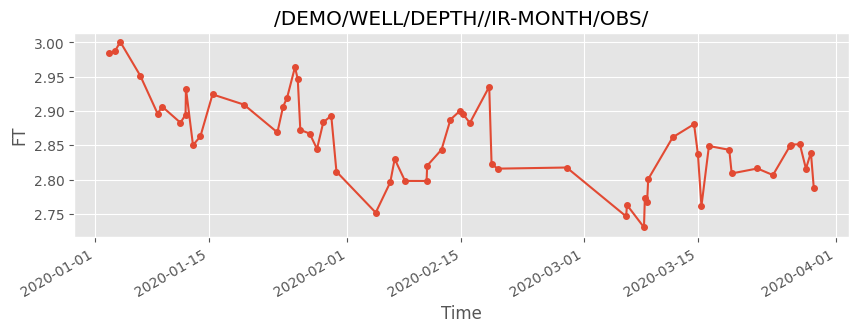

In [3]:
rng = np.random.default_rng(1)
times = pd.Timestamp('2020-01-01') + pd.to_timedelta(np.sort(rng.choice(np.arange(90*24*60), 60, replace=False)), unit='min')
readings = pd.Series(3 + np.cumsum(rng.normal(0, 0.05, times.size)), index=times)

dss_file.write(phl.IrregularTs.from_series('/DEMO/WELL/DEPTH//IR-MONTH/OBS/', readings, unit='FT'))
depth = dss_file.read('/DEMO/WELL/DEPTH//IR-MONTH/OBS/').to_series()
pd.testing.assert_series_equal(depth, readings.rename('DEPTH').rename_axis('Time'), check_freq=False)

ax = depth.plot(style='o-', ms=4, figsize=(10, 3), title='/DEMO/WELL/DEPTH//IR-MONTH/OBS/')
ax.set_ylabel('FT');

## Time window & replace
Writing replaces stored values inside the time span of the new record.

In [4]:
window = dss_file.read(stage.path, start='2020-01-02', end='2020-02-28')
assert window.values.tolist() == [3.4, 4.8]

dss_file.write(phl.IrregularTs(stage.path, pd.to_datetime(['2020-02-01 00:00:00']), [9.9], unit='FT'))
dss_file.read(stage.path).to_series()

Time
2020-01-01 00:13:00    3.1
2020-01-03 07:30:00    3.4
2020-02-01 00:00:00    9.9
2020-02-11 12:00:00    4.8
2020-02-29 23:59:00    4.2
2020-05-01 06:00:00    3.9
Name: STAGE, dtype: float64

In [5]:
dss_file.close()
print('all checks passed')

all checks passed
